# Firmas nivel 2: orden, geometría y aliasing
## Resumen
En simulación el nivel 2 separa orientación sin ruido; endpoints y momentos no distinguen pares reversos. Con ruido alto falla. Auditoría S2 de un componente del programa 13, sin evidencia operativa.
## Contexto y métodos
Trayectorias poligonales finitas en $\mathbb R^d$.
$S_1=\sum_i\Delta x_i$, $S_2=\sum_{i<j}\Delta x_i\otimes\Delta x_j+\frac12\sum_i\Delta x_i\otimes\Delta x_i$.
Composición de Chen: $(a,b)*(c,d)=(a+c,b+d+a\otimes c)$. Al añadir segmento $v$ se multiplica por $(v,v\otimes v/2)$.
Área: $A=(S_2^{12}-S_2^{21})/2$, oráculo independiente shoelace cerrando por cuerda.
### Supuestos
Etiqueta sintética de orientación latente antes del ruido. Los pares reversos tienen los mismos puntos y resúmenes marginales: cualquier clasificador determinista sobre dichos resúmenes predice igual para ambos, por lo que acierta exactamente uno. No se afirma reconstrucción ni innovación algorítmica mundial.
## Datos
Semilla 422; 100 pares por nivel de ruido. Los miembros del par no son independientes.

## Lectura de los resultados ejecutados

Se verificaron Chen, shuffle, reversión, escala y aliasing; la firma truncada no identifica toda trayectoria.

Resultados académicos adicionales (valores del experimento):

```json
{
  "lead_lag_checks": 100,
  "max_identity_error": 3.979039320256561e-13
}
```

Datos sintéticos. Esta sección acompaña las salidas guardadas y no es una medición comercial o bancaria.

In [1]:
import json, csv
from pathlib import Path
from IPython.display import display, Image
results=Path('results')
config=json.loads(Path('config.json').read_text())
config

Out[1]: 
{'seed': 422,
 'n_points': [8, 16, 32, 64, 128, 256],
 'replicates': 100,
 'noise_sd': [0, 0.05, 0.25, 1.0],
 'area_tolerance': 1e-10,
 'orientation_accuracy_threshold': 0.95}


## Resultados
Los CSV preservan réplicas y medidas. Shoelace es más específico y eficiente para área planar: no se pretende superarlo.

In [2]:
summary=json.loads((results/'summary.json').read_text())
summary

Out[2]: 
{'seed': 422,
 'samples': 800,
 'accuracy_by_noise': {'0': 1.0, '0.05': 1.0, '0.25': 1.0, '1.0': 0.7},
 'endpoint_accuracy': 0.5,
 'moments_accuracy': 0.5,
 'max_oracle_error': 1.0658141036401503e-14,
 'convergence_order': 1.999869639150011,
 'aliasing_dense_area': 6.280662313909504,
 'aliasing_four_segment_area': 0.0,
 'python': '3.12.14',
 'numpy': '2.3.5',
 'hardware': 'x86_64',
 'platform': 'Linux-6.18.55-x86_64-with-glibc2.39'}


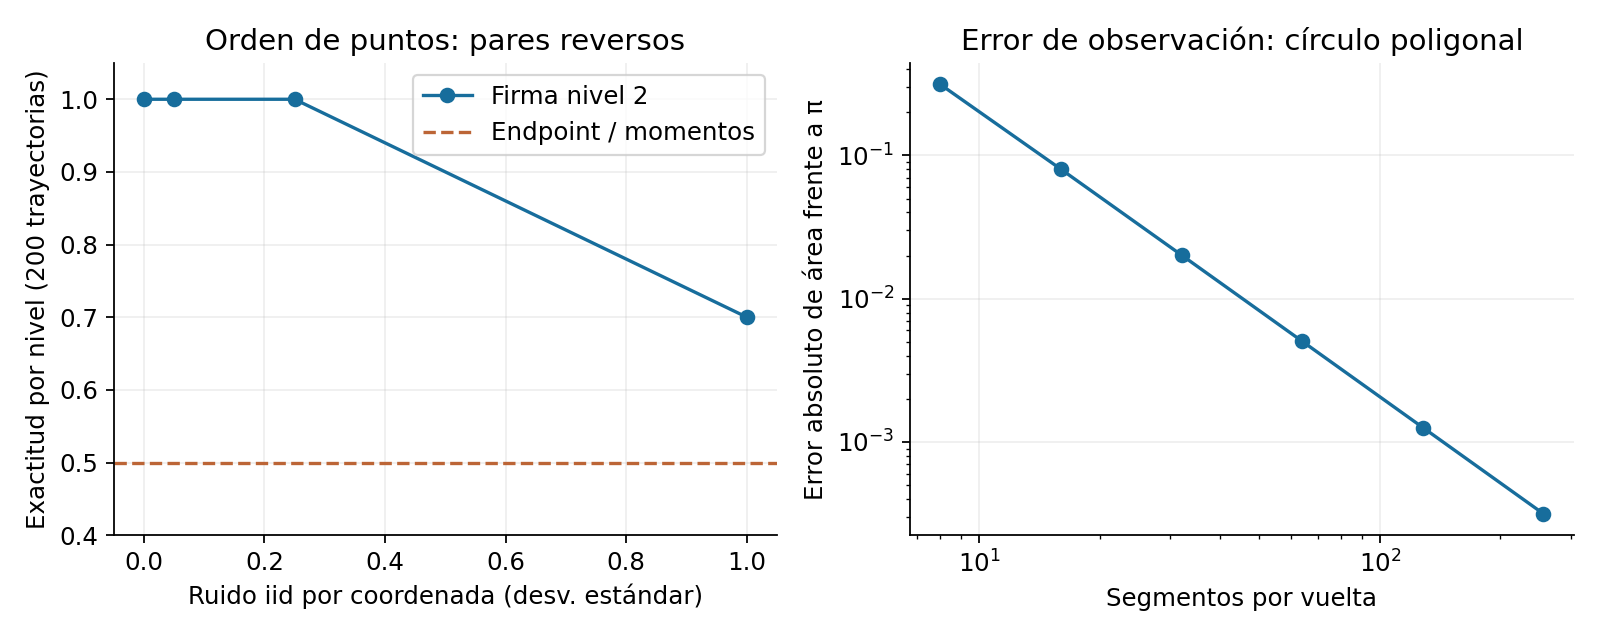

In [3]:
display(Image(filename=str(results/'audit.png')))

### Convergencia y recursos
El error frente a π es geométrico por observación poligonal. No es error de discretización de la recurrencia. La API conserva entrada batch; el estado recurrente requiere O(d²).

In [4]:
list(csv.DictReader((results/'convergence.csv').open()))

Out[4]: 
[{'segments': '8',
  'area': '2.8284271247461903',
  'polygon_exact': '2.82842712474619',
  'error_to_pi': '0.3131655288436028',
  'oracle_error': '4.440892098500626e-16'},
 {'segments': '16',
  'area': '3.0614674589207183',
  'polygon_exact': '3.0614674589207183',
  'error_to_pi': '0.08012519466907486',
  'oracle_error': '0.0'},
 {'segments': '32',
  'area': '3.121445152258052',
  'polygon_exact': '3.121445152258052',
  'error_to_pi': '0.020147501331741147',
  'oracle_error': '0.0'},
 {'segments': '64',
  'area': '3.136548490545939',
  'polygon_exact': '3.1365484905459393',
  'error_to_pi': '0.005044163043854244',
  'oracle_error': '4.440892098500626e-16'},
 {'segments': '128',
  'area': '3.140331156954752',
  'polygon_exact': '3.140331156954753',
  'error_to_pi': '0.0012614966350410484',
  'oracle_error': '8.881784197001252e-16'},
 {'segments': '256',
  'area': '3.141277250932771',
  'polygon_exact': '3.141277250932773',
  'error_to_pi': '0.00031540265702201253',
  'oracle_e

In [5]:
list(csv.DictReader((results/'scalability.csv').open()))

Out[5]: 
[{'segments': '64',
  'method': 'signature2',
  'seconds_median': '0.0010436929999286804',
  'peak_bytes': '2336'},
 {'segments': '64',
  'method': 'shoelace',
  'seconds_median': '0.00010037999982159818',
  'peak_bytes': '9304'},
 {'segments': '256',
  'method': 'signature2',
  'seconds_median': '0.003816696000058073',
  'peak_bytes': '2304'},
 {'segments': '256',
  'method': 'shoelace',
  'seconds_median': '0.0001032949999171251',
  'peak_bytes': '13912'},
 {'segments': '1024',
  'method': 'signature2',
  'seconds_median': '0.01581914999997025',
  'peak_bytes': '2972'},
 {'segments': '1024',
  'method': 'shoelace',
  'seconds_median': '0.00011765599992941134',
  'peak_bytes': '32376'},
 {'segments': '4096',
  'method': 'signature2',
  'seconds_median': '0.07039653400011048',
  'peak_bytes': '9116'},
 {'segments': '4096',
  'method': 'shoelace',
  'seconds_median': '0.00014316400006464391',
  'peak_bytes': '106104'}]


## Comprobaciones
Tests de Chen, shuffle, traslación, reversión, entradas inválidas y degeneración. Dos vueltas vistas con cuatro segmentos pierden el área: la exactitud numérica no corrige aliasing.

In [6]:
from src.signatures import signature, circle, signed_area
import numpy as np
a,b=signature(np.array([[0.,0.],[1.,2.],[0.,0.]]))
assert np.allclose(b,0)
assert summary['max_oracle_error'] < config['area_tolerance']
assert summary['accuracy_by_noise']['0'] >= config['orientation_accuracy_threshold']
print('Tree-like:', b.tolist())
print('Área densa:', signed_area(circle(256,turns=2)))
print('Área submuestreada:', signed_area(circle(4,turns=2)))

Tree-like: [[0.0, 0.0], [0.0, 0.0]]
Área densa: 6.280662313909504
Área submuestreada: 0.0


## Conclusiones
El nivel 2 añade orden frente a endpoints y momentos; no identifica caminos arbitrarios. Con ruido 1.0, 70% de exactitud refuta robustez universal. Falta validación externa. Bibliografía y verificación en referencias.bib y fuentes.md.

## Laboratorio ampliado — derivación, usos y refutación

Experimentos adicionales del 23 de octubre de 2026. Datos sintéticos; las cifras guardadas del estudio original se conservan y las nuevas se recalculan debajo.

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'figure.figsize':(8,4.6),'font.size':11,'axes.spines.top':False,
                     'axes.spines.right':False,'axes.grid':True,'grid.alpha':.18})
BLUE='#245B83'; GOLD='#B57A21'; GRAY='#4D5358'
rng_depth=np.random.default_rng(20261023)

### Firma truncada y orden temporal

Para incrementos $\Delta x_k$ de una trayectoria lineal a trozos:

$$S^1=\sum_k\Delta x_k,\quad S^2=\sum_{i<j}\Delta x_i\otimes\Delta x_j+\frac12\sum_k\Delta x_k\otimes\Delta x_k.$$

La composición de Chen es $(a,b)\star(c,d)=(a+c,b+d+a\otimes c)$. El área orientada es $(S^2_{12}-S^2_{21})/2$, en unidades de coordenada 1 por coordenada 2. Ni esta área ni una firma de nivel dos identifican una trayectoria completa.

### Chen frente a cálculo de trayectoria completa

Una partición conserva el punto de unión, sin repetir un desplazamiento.

In [8]:
from src.signatures import signature, compose, circle, signed_area, polygon_area
path_d=np.cumsum(rng_depth.normal(size=(100,2)),axis=0)
whole=signature(path_d)
split=compose(signature(path_d[:51]),signature(path_d[50:]))
assert all(np.allclose(a,b,atol=1e-10) for a,b in zip(whole,split))
print('Error de composición:',max(np.max(np.abs(a-b)) for a,b in zip(whole,split)))

Error de composición: 1.4210854715202004e-14


### Identidad shuffle y reversión

La parte simétrica queda determinada por el desplazamiento; el contenido nuevo de nivel dos está en la parte antisimétrica.

In [9]:
a_d,b_d=whole
shuffle=b_d+b_d.T-np.outer(a_d,a_d)
assert np.max(np.abs(shuffle))<1e-9
assert np.allclose(signature(path_d[::-1])[1],np.outer(a_d,a_d)-b_d)
print('Residual shuffle máximo:',np.max(np.abs(shuffle)))

Residual shuffle máximo: 2.842170943040401e-14


### Convergencia del área y aliasing

La referencia analítica de un círculo de radio uno con q vueltas es q*pi. El error de discretización no es incertidumbre estadística.

,vueltas,segmentos,area,error
0,1,4,2.00000,1.14159
1,1,8,2.82843,0.31317
2,1,16,3.06147,0.08013
3,1,32,3.12145,0.02015
4,1,64,3.13655,0.00504
5,1,128,3.14033,0.00126
6,1,256,3.14128,0.00032
7,2,4,0.00000,6.28319
8,2,8,4.00000,2.28319


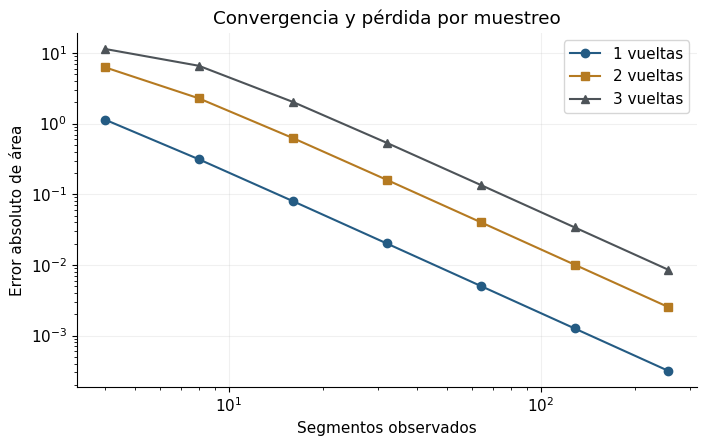

In [10]:
rows_d=[]
for turns in [1,2,3]:
    for n in [4,8,16,32,64,128,256]:
        path=circle(n,turns=turns)
        area=signed_area(path)
        assert abs(area-polygon_area(path))<1e-10
        rows_d.append({'vueltas':turns,'segmentos':n,'area':area,'error':abs(area-turns*np.pi)})
areas_d=pd.DataFrame(rows_d);display(areas_d.head(9).round(5))
fig,ax=plt.subplots()
for (turns,g),color,marker in zip(areas_d.groupby('vueltas'),[BLUE,GOLD,GRAY],['o','s','^']):
    ax.loglog(g.segmentos,g.error,marker=marker,color=color,label=f'{turns} vueltas')
ax.set(xlabel='Segmentos observados',ylabel='Error absoluto de área',title='Convergencia y pérdida por muestreo');ax.legend();plt.show()

### Misma bolsa de puntos, orden diferente

Una representación que borra el orden no puede recuperar orientación. Aquí se compara la misma trayectoria con su reversa.

{'area_ida': 3.128689300804617, 'area_reversa': -3.1286893008046173}


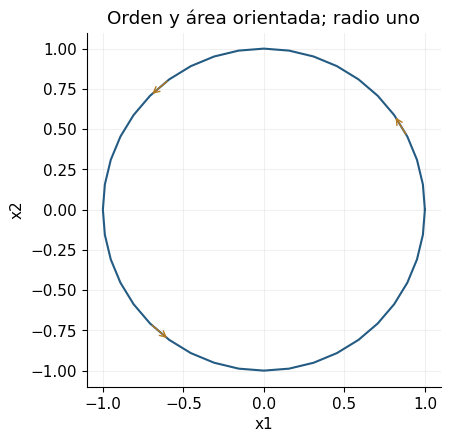

In [11]:
path=circle(40)
forward=signed_area(path); backward=signed_area(path[::-1])
assert np.allclose(path.mean(0),path[::-1].mean(0))
assert np.isclose(forward,-backward)
fig,ax=plt.subplots();ax.plot(path[:,0],path[:,1],color=BLUE)
for i in [3,14,25]:
    ax.annotate('',xy=path[i+1],xytext=path[i],arrowprops={'arrowstyle':'->','color':GOLD})
ax.set(aspect='equal',xlabel='x1',ylabel='x2',title='Orden y área orientada; radio uno');plt.show()
print({'area_ida':forward,'area_reversa':backward})

### Contraejemplo de identificabilidad

Una excursión recta y su retorno tienen firma truncada nula, como una trayectoria constante.

In [12]:
excursion=np.array([[0.,0.],[2.,3.],[0.,0.]])
constant=np.zeros((3,2))
assert all(np.allclose(a,b) for a,b in zip(signature(excursion),signature(constant)))
print('Trayectorias distintas; misma firma de nivel 2.')

Trayectorias distintas; misma firma de nivel 2.


### Uso y extensiones

Útil como feature de orden y área en flujos o señales; no es detector de fraude ni reconstructora universal. Antes de ampliar nivel, estudiar muestreo irregular, normalización por escala y fuga temporal. Agregar tiempo como coordenada cambia la representación y requiere otro experimento.

### Preguntas para extender el estudio

1. ¿Qué supuesto permite el resultado y qué contraejemplo lo destruye?
2. ¿Qué cambia al separar entrenamiento, calibración y evaluación por fecha?
3. ¿Qué pérdidas, costos o acciones no están representados?
4. ¿Qué evidencia real haría abandonar este modelo?

Las salidas anteriores son el resultado de esta ejecución; las pruebas locales no establecen validez empírica.

### Escala, traslación y parametrización

Trasladar coordenadas no cambia incrementos. Escalar todas las coordenadas por k multiplica nivel uno por k y nivel dos por k².

In [13]:
base_path=circle(80)
base_a,base_b=signature(base_path)
shift_a,shift_b=signature(base_path+np.array([100.,-25.]))
scale_a,scale_b=signature(3*base_path)
assert np.allclose(base_a,shift_a,atol=1e-10)
assert np.allclose(base_b,shift_b,atol=1e-10)
assert np.allclose(scale_b,9*base_b,atol=1e-10)
print('Área original:',signed_area(base_path),'Área escala 3:',signed_area(3*base_path))

Área original: 3.138363829113799 Área escala 3: 28.245274462024184


### Clasificación de orientación con ruido

Monte Carlo sobre pares ida/reversa con ruido independiente. Los intervalos Wilson son marginales por nivel de ruido, no simultáneos.

,sigma,accuracy,lo,hi
0,0.0,1.000,0.9812,1.0000
1,0.1,1.000,0.9812,1.0000
2,0.3,1.000,0.9812,1.0000
3,0.8,0.830,0.7718,0.8757
4,1.5,0.625,0.5561,0.6891


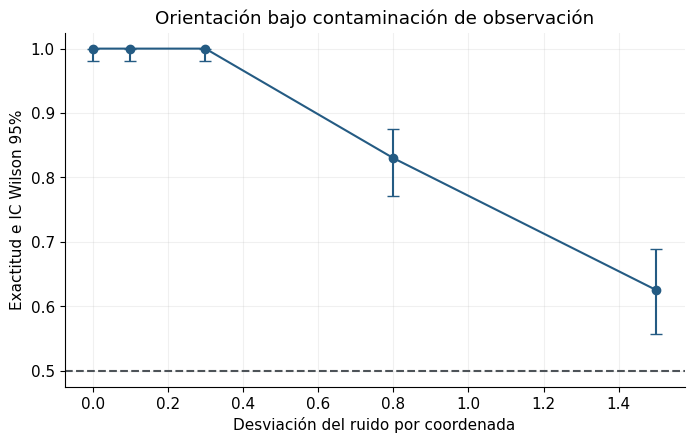

In [14]:
from scipy.stats import binomtest
noise_rows=[]
for sigma in [0,.1,.3,.8,1.5]:
    correct=0
    for repeat in range(200):
        orientation=1 if repeat%2==0 else -1
        noisy=circle(40,orientation=orientation)+rng_depth.normal(0,sigma,(41,2))
        noisy[-1]=noisy[0]
        correct+=np.sign(signed_area(noisy))==orientation
    interval=binomtest(correct,200).proportion_ci(method='wilson')
    noise_rows.append({'sigma':sigma,'accuracy':correct/200,'lo':interval.low,'hi':interval.high})
noise_table=pd.DataFrame(noise_rows)
display(noise_table.round(4))
fig,ax=plt.subplots()
ax.errorbar(noise_table.sigma,noise_table.accuracy,yerr=[noise_table.accuracy-noise_table.lo,noise_table.hi-noise_table.accuracy],fmt='o-',capsize=4,color=BLUE)
ax.axhline(.5,color=GRAY,ls='--')
ax.set(xlabel='Desviación del ruido por coordenada',ylabel='Exactitud e IC Wilson 95%',title='Orientación bajo contaminación de observación')
plt.show()

### Estado recurrente y particiones irregulares

La composición se verifica con cortes no equiespaciados sobre una misma trayectoria; no recupera datos que nunca se observaron.

In [15]:
x=path_d
cuts=[0,7,19,66,len(x)-1]
acc=signature(x[:1])
for left,right in zip(cuts[:-1],cuts[1:]):
    part=signature(x[left:right+1])
    acc=compose(acc,part)
assert all(np.allclose(a,b,atol=1e-9) for a,b in zip(acc,signature(x)))
print('Particiones:',cuts,'residual:',np.max(np.abs(acc[1]-signature(x)[1])))

Particiones: [0, 7, 19, 66, 99] residual: 2.842170943040401e-14


### Interpretación de las pruebas adicionales

Cada experimento modifica un supuesto concreto. Las comparaciones conservan denominadores, unidades y desconocidos; los resultados negativos forman parte de la evidencia. Las simulaciones no convierten un diseño en un sistema operativo ni sustituyen validación independiente con datos aprobados.

## Ampliación académica: literatura, fórmulas y experimento

Consulta bibliográfica del 23 de octubre de 2026. Se distingue método publicado, derivación propia y experimento sintético. El [mapa bibliográfico](https://github.com/Jose85100/Portafolio/blob/research/2026-10-23-multi-domain-cycle/reviews/2026-10-23-academic/README.md) en la raíz del repositorio registra publicaciones, acceso y brechas; las fuentes específicas se enlazan debajo.

### Lead–lag para conservar variación cuadrática discreta

Fuente publicada: [Chevyrev y Kormilitzin, Springer Finance, 2025, §3.1.14](https://doi.org/10.1007/978-3-031-97239-3_1), desarrollo del preprint de 2016. Es un capítulo académico publicado, no un artículo de revista de 2016.

Para la secuencia $x_0,\ldots,x_n$, usamos los vértices $(x_i,x_i)\to(x_{i+1},x_i)\to(x_{i+1},x_{i+1})$:

$$2A_{lead,lag}=\sum_{i=0}^{n-1}(x_{i+1}-x_i)^2.$$

El factor dos depende de definir $A=(S^2_{12}-S^2_{21})/2$. Es variación realizada sobre la malla observada, no varianza muestral ni recuperación de incrementos no observados.

### Identidad con la implementación de firma existente

Se construye el embedding y se contrasta con la suma directa, sin introducir una biblioteca externa de firmas.

In [16]:
def lead_lag(values):
    values=np.asarray(values,float)
    if values.ndim!=1 or not len(values) or not np.isfinite(values).all():
        raise ValueError('finite scalar sequence required')
    vertices=[[values[0],values[0]]]
    for old,new in zip(values[:-1],values[1:]):
        vertices.extend([[new,old],[new,new]])
    return np.asarray(vertices)

paper_rng=np.random.default_rng(2302)
identity_errors=[]
for n in [1,4,16,64,256]:
    for repeat in range(20):
        stream=np.r_[0,np.cumsum(paper_rng.normal(size=n))]
        signature_value=2*signed_area(lead_lag(stream))
        direct_value=np.sum(np.diff(stream)**2)
        identity_errors.append(abs(signature_value-direct_value))
assert max(identity_errors)<1e-9
print('Error máximo de identidad:',max(identity_errors))

Error máximo de identidad: 3.979039320256561e-13


### Misma variación, menor frecuencia de muestreo

Una sola realización no garantiza monotonía al agregar incrementos. Se muestran cuantiles Monte Carlo y no bandas de confianza de una volatilidad financiera.

ACADEMIC_METRICS:{"lead_lag_checks": 100, "max_identity_error": 3.979039320256561e-13}


,mean,std
paso,,
1,0.9798,0.0951
2,0.9800,0.1268
4,0.9715,0.1809
8,0.9699,0.2417
16,1.0026,0.3614
32,0.9488,0.4835


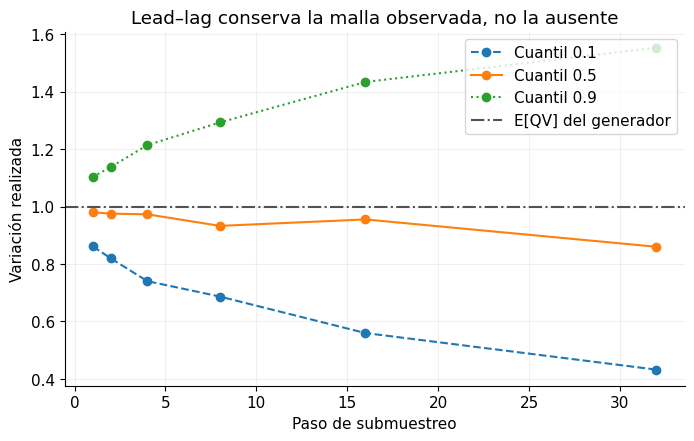

In [17]:
qv_rows=[]
for repeat in range(150):
    stream=np.r_[0,np.cumsum(paper_rng.normal(0,1/np.sqrt(256),256))]
    for step in [1,2,4,8,16,32]:
        sampled=stream[::step]
        qv_rows.append({'paso':step,'QV':2*signed_area(lead_lag(sampled))})
qv_table=pd.DataFrame(qv_rows)
summary_qv=qv_table.groupby('paso').QV.agg(['mean','std'])
display(summary_qv.round(4))
fig,ax=plt.subplots()
for q,style in [(.1,'--'),(.5,'-'),(.9,':')]:
    v=qv_table.groupby('paso').QV.quantile(q)
    ax.plot(v.index,v.values,ls=style,marker='o',label=f'Cuantil {q:g}')
ax.axhline(1,color=GRAY,ls='-.',label='E[QV] del generador')
ax.set(xlabel='Paso de submuestreo',ylabel='Variación realizada',title='Lead–lag conserva la malla observada, no la ausente')
ax.legend();plt.show()
import json
print('ACADEMIC_METRICS:'+json.dumps({'lead_lag_checks':len(identity_errors),'max_identity_error':float(max(identity_errors))}))

### Ideas y criterio de cierre

Extender a covariación multicanal, comparar con sumas realizadas directas y ajustar un clasificador con separación temporal. La identidad no demuestra que firmas predigan mejor; tampoco reemplaza corrección de microestructura en precios reales.